# M3 — Weekly bidding agent (mFRR)

General EDA is in `m3_eda_bidbook.ipynb`. This notebook only holds what the bidding study needs.

Sections
1. The task
2. The data and the split
3. How the weekly price moves
4. The bidders
5. Results on 2025
6. Final test on 2026 (empty until the end)

## 1. The task

One bidder sells **1 MW** in every **weekly** mFRR auction. It chooses one number per week: its **price**.

- bid **strictly below** the marginal price → wins and earns **its own bid**
- otherwise (equal included) → earns **0**
- goal: the highest **yearly revenue**, upwards and downwards **separately**

| Week | Bid | Marginal price | Result | Earns |
|---|---|---|---|---|
| 1 | 90 | 100 | wins | 90 |
| 2 | 100 | 100 | equal: loses | 0 |
| 3 | 70 | 80 | wins | 70 |

Earned 160 out of a best possible 280 = **57 % of best**. "Best possible" is the sum of the marginal prices: a ceiling no bid can quite reach.

**Simplification:** in reality 95 % of weekly bids strictly below the marginal price are accepted, not 100 % (see the EDA, section 4).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data.data import build_auctions
from src.evaluation.revenue import score_bids, select_weekly, summarise
from src.models.bidders import (CHOOSE_YEAR, FINAL_YEAR, LAST_LEARN_YEAR,
                                DiscountBidder, LastPriceBidder, add_last_price)

C1, C2, GREY, INK = "#2a78d6", "#eb6834", "#9a9893", "#52514e"
DIR_COLOR = {"downwards": C1, "upwards": C2}
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "legend.frameon": False,
})

## 2. The data and the split

One row per weekly auction and direction. The bidder may use only what was **published before its deadline**.

| Years | Role |
|---|---|
| 2019–2024 | the bidder **learns** |
| 2025 | we **compare** versions and choose settings |
| 2026 | **final test**, scored once, at the end |

A week that crosses New Year belongs to the year in Swissgrid's auction name (week of 30 Dec 2024 → `TRL_25_KW01` → 2025).

In [2]:
weekly_all = add_last_price(select_weekly(build_auctions()))
role = {**{y: "learn" for y in range(2019, LAST_LEARN_YEAR + 1)}, CHOOSE_YEAR: "compare", FINAL_YEAR: "final test"}
weeks = weekly_all.groupby(["year", "direction"]).size().unstack()
weeks.insert(0, "role", weeks.index.map(role))
display(weeks)

# the final year is put aside here: nothing below can look at its prices
weekly = weekly_all[weekly_all["year"] < FINAL_YEAR].copy()
no_last = weekly["last_price"].isna()
print(f"{no_last.sum()} auctions have no last known price (first week of each direction) and are skipped")
weekly = weekly[~no_last]

direction,role,downwards,upwards
year,,,
2019,learn,51,51
2020,learn,53,53
2021,learn,52,52
2022,learn,52,52
2023,learn,52,52
2024,learn,52,52
2025,compare,52,52
2026,final test,46,46


2 auctions have no last known price (first week of each direction) and are skipped


## 3. How the weekly price moves

`ratio` = this week's marginal price ÷ last known price. **Below 1** the price fell, so bidding the last price loses.

*Example:* last price 100, new price 95 → ratio 0.95. Bidding 100 loses; bidding 80 wins and earns 80.

Learning years only (2019–2024).

In [3]:
learn = weekly[weekly["year"] <= LAST_LEARN_YEAR].copy()
learn["ratio"] = learn["marginal"] / learn["last_price"]
rows = {}
for d, g in learn.groupby("direction"):
    rows[d] = {"weeks": f"{len(g)}",
               "price fell or stayed equal": f"{(g['ratio'] <= 1).mean():.0%}",
               "price rose": f"{(g['ratio'] > 1).mean():.0%}",
               "typical (median) change": f"{g['ratio'].median() - 1:+.1%}",
               "fell by more than 10 %": f"{(g['ratio'] < 0.9).mean():.0%}",
               "fell by more than 20 %": f"{(g['ratio'] < 0.8).mean():.0%}",
               "rose by more than 20 %": f"{(g['ratio'] > 1.2).mean():.0%}"}
pd.DataFrame(rows)

,downwards,upwards
weeks,311,311
price fell or stayed equal,65%,69%
price rose,35%,31%
typical (median) change,-6.1%,-4.3%
fell by more than 10 %,34%,20%
fell by more than 20 %,15%,4%
rose by more than 20 %,19%,12%


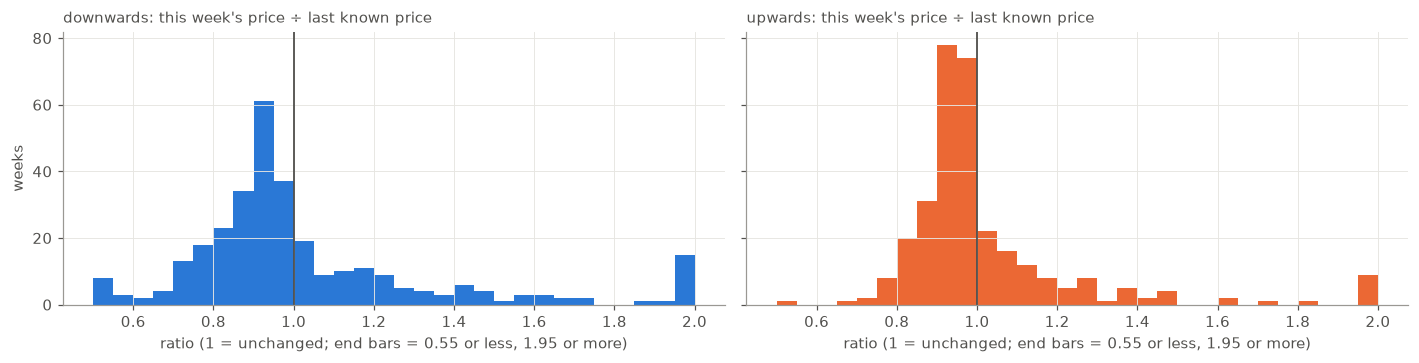

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), sharey=True)
bins = np.arange(0.5, 2.001, 0.05)
for ax, (d, g) in zip(axes, learn.groupby("direction")):
    ax.hist(g["ratio"].clip(0.5, 1.999), bins=bins, color=DIR_COLOR[d])
    ax.axvline(1, color=INK, linewidth=1.2)
    ax.set_title(f"{d}: this week's price ÷ last known price", loc="left", fontsize=10, color=INK)
    ax.set_xlabel("ratio (1 = unchanged; end bars = 0.55 or less, 1.95 or more)")
axes[0].set_ylabel("weeks")
fig.tight_layout()

**Takeaway:** most weeks the price slips a little, and sometimes it jumps. Bidding the last price therefore usually lands just above the new price and loses; a discount gives up a bit each week but wins almost always.

## 4. The bidders

| Bidder | Bid | Learns |
|---|---|---|
| **Last price** | the last known marginal price | nothing |
| **Discount** | factor × last known price | one factor per direction, on 2019–2024 |

*Example:* last price 100, factor 0.80 → bids 80. New price 95 → wins 80. New price 75 → loses.

The factor is the one with the best **average yearly % of best**, so every year counts the same and the very expensive 2022 does not decide alone.

factor chosen on 2019-2024: {'downwards': 0.74, 'upwards': 0.8}


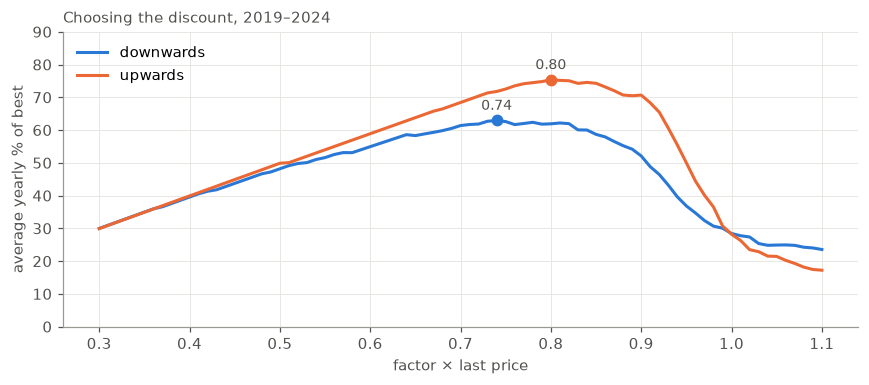

In [5]:
discount = DiscountBidder().fit(weekly)
print("factor chosen on 2019-2024:", discount.factors_)

fig, ax = plt.subplots(figsize=(8, 3.6))
for d, g in learn.groupby("direction"):
    curve = [DiscountBidder._mean_yearly_pct(g, f) for f in discount.grid]
    ax.plot(discount.grid, curve, color=DIR_COLOR[d], linewidth=2, label=d)
    best = discount.factors_[d]
    ax.scatter([best], [max(curve)], s=45, color=DIR_COLOR[d], zorder=3)
    ax.annotate(f"{best:.2f}", (best, max(curve)), textcoords="offset points", xytext=(0, 7),
                ha="center", fontsize=9, color=INK)
ax.set_ylim(0, 90)
ax.set_xlabel("factor × last price"); ax.set_ylabel("average yearly % of best")
ax.set_title("Choosing the discount, 2019–2024", loc="left", fontsize=10, color=INK)
ax.legend(loc="upper left"); fig.tight_layout()

Bidding too low leaves money on the table (left side); bidding too close to the last price loses too often (the drop on the right).

## 5. Results on 2025

2025 was not used to choose the factors. Revenue is in CHF for 1 MW over the year.

In [6]:
def results(year: int) -> pd.DataFrame:
    if year >= FINAL_YEAR:
        raise ValueError("the final year is scored only once, at the end (section 6)")
    due = weekly[weekly["year"] == year]
    rows = []
    for bidder in (LastPriceBidder(), discount):
        t = summarise(score_bids(due, bidder.bid(due)))
        rows.append(t.assign(bidder=bidder.name))
    t = pd.concat(rows)
    return pd.DataFrame({
        "direction": t["direction"], "bidder": t["bidder"],
        "won": [f"{w} of {n}" for w, n in zip(t["wins"], t["auctions"])],
        "revenue (CHF)": t["revenue"].map("{:,.0f}".format),
        "best possible (CHF)": t["best_possible"].map("{:,.0f}".format),
        "% of best": t["pct_of_best"].map("{:.1f} %".format),
    }).sort_values(["direction", "bidder"], ascending=[True, False]).set_index(["direction", "bidder"])

results(CHOOSE_YEAR)

won revenue (CHF) best possible (CHF) % of best
direction bidder                                                          
downwards last_price  13 of 52        25,621              91,265    28.1 %
          discount    47 of 52        62,021              91,265    68.0 %
upwards   last_price  17 of 52         4,814              14,813    32.5 %
          discount    49 of 52        10,962              14,813    74.0 %

Same two bidders in every year so far (% of best). The discount was chosen on 2019–2024, so only **2025** is a fair check for it.

In [7]:
rows = []
for bidder in (LastPriceBidder(), discount):
    t = summarise(score_bids(weekly, bidder.bid(weekly)))
    rows.append(t.assign(bidder=bidder.name))
t = pd.concat(rows).pivot(index="year", columns=["direction", "bidder"], values="pct_of_best")
t = t.reindex(columns=[(d, b) for d in ("downwards", "upwards") for b in ("last_price", "discount")])
t.map("{:.0f} %".format)

direction  downwards             upwards         
bidder    last_price discount last_price discount
year                                             
2019            27 %     67 %       25 %     78 %
2020            23 %     64 %       29 %     68 %
2021            41 %     63 %       38 %     68 %
2022            33 %     60 %       26 %     79 %
2023            27 %     66 %       30 %     81 %
2024            20 %     57 %       22 %     78 %
2025            28 %     68 %       32 %     74 %

**To beat on 2025: 68 % of best downwards and 74 % upwards** (discount bidder).

## 6. Final test on 2026

Not run yet. It is scored once, when every bidder is finished, with the settings chosen above. 2026 has 46 weeks so far, so it is compared by % of best, not by yearly CHF.